In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import sys
import platform
import shutil

# Set the path to your Google Drive
DRIVE_BASE_PATH = "/content/drive/MyDrive"
PROJECT_FOLDER = os.path.join(DRIVE_BASE_PATH, "Multimedia_Group_Project")

def setup_secure_environment():
    # Create the project folder in your Drive if it doesn't exist
    os.makedirs(PROJECT_FOLDER, exist_ok=True)

    # Change the default working directory to your Drive folder
    os.chdir(PROJECT_FOLDER)

    print("--- System Environment ---")
    print(f"Python version: {sys.version.split()[0]}")
    print(f"Operating system: {platform.system()}")
    print(f"✅ New working directory (Saved to Drive): {os.getcwd()}")
    print("-" * 30)

def check_drive_storage():
    # Check storage space on Google Drive instead of Colab's temporary disk
    try:
        total, used, free = shutil.disk_usage(DRIVE_BASE_PATH)

        print("\n--- Storage Information (Google Drive) ---")
        print(f"Total: {total / (1024**3):.2f} GB")
        print(f"Used: {used / (1024**3):.2f} GB")
        print(f"Free: {free / (1024**3):.2f} GB")
    except FileNotFoundError:
        print("\n❌ Error: Google Drive is not mounted.")

setup_secure_environment()
check_drive_storage()

--- System Environment ---
Python version: 3.13.18
Operating system: Linux
✅ New working directory (Saved to Drive): /content/drive/MyDrive/Multimedia_Group_Project
------------------------------

--- Storage Information (Google Drive) ---
Total: 107.72 GB
Used: 20.58 GB
Free: 87.12 GB


In [ ]:
import os

# Set base path directly to your Google Drive to prevent data loss
base_path = "/content/drive/MyDrive/COCO_Project"

folders = [
    "raw",
    "images/train",
    "images/validation",
    "annotations",
    "cleaned",
    "reports"
]

# Create the folder structure inside your Drive
for folder in folders:
    path = os.path.join(base_path, folder)
    os.makedirs(path, exist_ok=True)

print("Project folders created successfully in Google Drive!")

# Display the directory tree
for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    # Fixed the syntax error here (added * for string multiplication)
    print("  " * level + os.path.basename(root) + "/")

Project folders created successfully in Google Drive!
COCO_Project/
  reports/
  images/
    train/
    validation/
  annotations/
  cleaned/
  raw/


In [ ]:
import os
import urllib.request

annotation_url = (
    "http://images.cocodataset.org/annotations/"
    "annotations_trainval2017.zip"
)

# Set the download path directly to your Google Drive folder
download_path = "/content/drive/MyDrive/COCO_Project/raw/annotations_trainval2017.zip"

print("Downloading COCO annotations...")

urllib.request.urlretrieve(annotation_url, download_path)

print("Download completed!")
print("File size:",
      round(os.path.getsize(download_path) / (1024**2), 2),
      "MB")

Download completed!
File size: 241.19 MB


In [ ]:
import zipfile
import os

# Update both paths to point directly to your Google Drive
zip_path = "/content/drive/MyDrive/COCO_Project/raw/annotations_trainval2017.zip"
extract_path = "/content/drive/MyDrive/COCO_Project/annotations"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Annotations extracted successfully!")

print("\nExtracted files:")
for file in os.listdir(extract_path):
    print(file)

Annotations extracted successfully!

Extracted files:
annotations


In [ ]:
import json

# Update the path to read the file directly from your Google Drive
caption_path = (
    "/content/drive/MyDrive/COCO_Project/annotations/annotations/"
    "captions_train2017.json"
)

with open(caption_path, "r") as file:
    coco_data = json.load(file)

print("Dataset information:")
print("Images:", len(coco_data["images"]))
print("Annotations:", len(coco_data["annotations"]))

print("\nFirst image:")
print(coco_data["images"][0])

print("\nFirst caption:")
print(coco_data["annotations"][0])

Dataset information:
Images: 118287
Annotations: 591753

First image:
{'license': 3, 'file_name': '000000391895.jpg', 'coco_url': 'http://images.cocodataset.org/train2017/000000391895.jpg', 'height': 360, 'width': 640, 'date_captured': '2013-11-14 11:18:45', 'flickr_url': 'http://farm9.staticflickr.com/8186/8119368305_4e622c8349_z.jpg', 'id': 391895}

First caption:
{'image_id': 203564, 'id': 37, 'caption': 'A bicycle replica with a clock as the front wheel.'}


In [ ]:
from collections import defaultdict

# Create an empty dictionary
captions_by_image = defaultdict(list)

# Group captions according to their image IDs
for annotation in coco_data["annotations"]:
    image_id = annotation["image_id"]
    caption = annotation["caption"]
    captions_by_image[image_id].append(caption)

# Choose the first image from our images collection
first_image = coco_data["images"][0]
image_id = first_image["id"]

print("Image filename:", first_image["file_name"])
print("Image ID:", image_id)

print("\nCaptions belonging to this image:")

for i, caption in enumerate(captions_by_image[image_id], 1):
    print(f"{i}. {caption}")

Image filename: 000000391895.jpg
Image ID: 391895

Captions belonging to this image:
1. A man with a red helmet on a small moped on a dirt road. 
2. Man riding a motor bike on a dirt road on the countryside.
3. A man riding on the back of a motorcycle.
4. A dirt path with a young person on a motor bike rests to the foreground of a verdant area with a bridge and a background of cloud-wreathed mountains. 
5. A man in a red shirt and a red hat is on a motorcycle on a hill side.


In [ ]:
caption_counts = [
    len(captions)
    for captions in captions_by_image.values()
]

print("Number of images with captions:", len(caption_counts))
print("Minimum captions per image:", min(caption_counts))
print("Maximum captions per image:", max(caption_counts))
print("Average captions per image:",
      sum(caption_counts) / len(caption_counts))

Number of images with captions: 118287
Minimum captions per image: 5
Maximum captions per image: 7
Average captions per image: 5.002688376575617


In [ ]:
from collections import Counter

distribution = Counter(caption_counts)

for number, images in sorted(distribution.items()):
    percentage = images / len(caption_counts) * 100

    print(
        f"{number} captions: "
        f"{images:,} images ({percentage:.2f}%)"
    )

5 captions: 117,972 images (99.73%)
6 captions: 312 images (0.26%)
7 captions: 3 images (0.00%)


In [ ]:
import os
import glob

# Update the search path to look inside your Google Drive
search_path = "/content/drive/MyDrive/COCO_Project/annotations"

matches = glob.glob(
    os.path.join(search_path, "**", "instances_train2017.json"),
    recursive=True
)

print("Matching files:", len(matches))

for path in matches:
    print(path)

Matching files: 1
/content/drive/MyDrive/COCO_Project/annotations/annotations/instances_train2017.json


Image successfully saved to: /content/drive/MyDrive/COCO_Project/images/train/000000391895.jpg


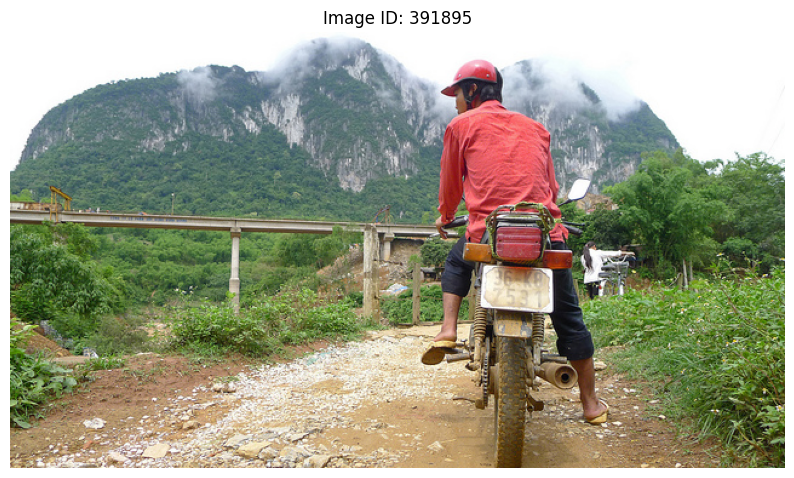

In [ ]:
import os
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Select our first image
image_info = coco_data["images"][0]

# Get its download URL
image_url = image_info["coco_url"]

# Download the image
response = requests.get(image_url, timeout=30)
response.raise_for_status()

# Open the image
img = Image.open(BytesIO(response.content))

# --- NEW: Save the image to your Google Drive ---
save_dir = "/content/drive/MyDrive/COCO_Project/images/train"
save_path = os.path.join(save_dir, image_info["file_name"])

# Save the physical image file to your Drive
img.save(save_path)
print(f"Image successfully saved to: {save_path}")
# ------------------------------------------------

# Display it
plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Image ID: {image_info['id']}")
plt.show()

In [ ]:
import json

instances_path = matches[0]

with open(instances_path, "r") as file:
    instances_data = json.load(file)

print("Images:", len(instances_data["images"]))
print("Object annotations:", len(instances_data["annotations"]))
print("Categories:", len(instances_data["categories"]))

Images: 118287
Object annotations: 860001
Categories: 80


In [ ]:
for category in instances_data["categories"]:
    print(category["id"], ":", category["name"])

1 : person
2 : bicycle
3 : car
4 : motorcycle
5 : airplane
6 : bus
7 : train
8 : truck
9 : boat
10 : traffic light
11 : fire hydrant
13 : stop sign
14 : parking meter
15 : bench
16 : bird
17 : cat
18 : dog
19 : horse
20 : sheep
21 : cow
22 : elephant
23 : bear
24 : zebra
25 : giraffe
27 : backpack
28 : umbrella
31 : handbag
32 : tie
33 : suitcase
34 : frisbee
35 : skis
36 : snowboard
37 : sports ball
38 : kite
39 : baseball bat
40 : baseball glove
41 : skateboard
42 : surfboard
43 : tennis racket
44 : bottle
46 : wine glass
47 : cup
48 : fork
49 : knife
50 : spoon
51 : bowl
52 : banana
53 : apple
54 : sandwich
55 : orange
56 : broccoli
57 : carrot
58 : hot dog
59 : pizza
60 : donut
61 : cake
62 : chair
63 : couch
64 : potted plant
65 : bed
67 : dining table
70 : toilet
72 : tv
73 : laptop
74 : mouse
75 : remote
76 : keyboard
77 : cell phone
78 : microwave
79 : oven
80 : toaster
81 : sink
82 : refrigerator
84 : book
85 : clock
86 : vase
87 : scissors
88 : teddy bear
89 : hair drier
90 :

In [ ]:
category_mapping = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

print("Category 1:", category_mapping[1])
print("Category 17:", category_mapping[17])
print("Category 90:", category_mapping[90])

Category 1: person
Category 17: cat
Category 90: toothbrush


In [ ]:
category_mapping[17]

'cat'

In [ ]:
from collections import Counter

category_counts = Counter()

for annotation in instances_data["annotations"]:
    category_counts[annotation["category_id"]] += 1

print("Most frequent categories:\n")

for category_id, count in category_counts.most_common(15):
    name = category_mapping[category_id]
    print(f"{name}: {count:,} annotations")

Most frequent categories:

person: 262,465 annotations
car: 43,867 annotations
chair: 38,491 annotations
book: 24,715 annotations
bottle: 24,342 annotations
cup: 20,650 annotations
dining table: 15,714 annotations
bowl: 14,358 annotations
traffic light: 12,884 annotations
handbag: 12,354 annotations
umbrella: 11,431 annotations
bird: 10,806 annotations
boat: 10,759 annotations
truck: 9,973 annotations
bench: 9,838 annotations


In [ ]:
from collections import defaultdict

# Create a set of image IDs for each category
category_images = defaultdict(set)

for annotation in instances_data["annotations"]:
    category_id = annotation["category_id"]
    image_id = annotation["image_id"]
    category_images[category_id].add(image_id)

print("Images containing each category:\n")

for category_id, image_ids in sorted(
    category_images.items(),
    key=lambda item: len(item[1]),
    reverse=True
):
    name = category_mapping[category_id]
    print(f"{name}: {len(image_ids):,} images")

Images containing each category:

person: 64,115 images
chair: 12,774 images
car: 12,251 images
dining table: 11,837 images
cup: 9,189 images
bottle: 8,501 images
bowl: 7,111 images
handbag: 6,841 images
truck: 6,127 images
bench: 5,570 images
backpack: 5,528 images
book: 5,332 images
cell phone: 4,803 images
sink: 4,678 images
clock: 4,659 images
tv: 4,561 images
potted plant: 4,452 images
couch: 4,423 images
dog: 4,385 images
knife: 4,326 images
sports ball: 4,262 images
traffic light: 4,139 images
cat: 4,114 images
umbrella: 3,968 images
bus: 3,952 images
tie: 3,810 images
bed: 3,682 images
vase: 3,593 images
train: 3,588 images
fork: 3,555 images
spoon: 3,529 images
laptop: 3,524 images
motorcycle: 3,502 images
surfboard: 3,486 images
skateboard: 3,476 images
tennis racket: 3,394 images
toilet: 3,353 images
bicycle: 3,252 images
bird: 3,237 images
pizza: 3,166 images
skis: 3,082 images
remote: 3,076 images
boat: 3,025 images
airplane: 2,986 images
horse: 2,941 images
cake: 2,925 im

In [ ]:
import os
import numpy as np

# 1. Get all image IDs
image_ids = [image["id"] for image in instances_data["images"]]

# 2. Get category IDs
category_ids = sorted(category_mapping.keys())

# 3. Create indexes
image_index = {
    image_id: index
    for index, image_id in enumerate(image_ids)
}

category_index = {
    category_id: index
    for index, category_id in enumerate(category_ids)
}

# 4. Create an empty matrix
Y = np.zeros(
    (len(image_ids), len(category_ids)),
    dtype=np.uint8
)

# 5. Mark the categories present in each image
for annotation in instances_data["annotations"]:
    i = image_index[annotation["image_id"]]
    j = category_index[annotation["category_id"]]
    Y[i, j] = 1

print("Matrix shape:", Y.shape)
print("Number of images:", Y.shape[0])
print("Number of categories:", Y.shape[1])
print("Matrix memory:", Y.nbytes / 1024**2, "MB")

# --- NEW: Save the matrix to your Google Drive ---
save_path = "/content/drive/MyDrive/COCO_Project/cleaned/category_matrix.npy"
np.save(save_path, Y)
print(f"Matrix successfully saved to: {save_path}")
# -------------------------------------------------

Matrix shape: (118287, 80)
Number of images: 118287
Number of categories: 80
Matrix memory: 9.024581909179688 MB
Matrix successfully saved to: /content/drive/MyDrive/COCO_Project/cleaned/category_matrix.npy


In [ ]:
import pandas as pd

# Convert the first 10 rows into a readable table
category_names = [
    category_mapping[category_id]
    for category_id in category_ids
]

matrix_preview = pd.DataFrame(
    Y[:10],
    columns=category_names
)

matrix_preview.insert(0, "image_id", image_ids[:10])

display(matrix_preview)

# --- NEW: Save the table as a CSV file to your Google Drive ---
save_path = "/content/drive/MyDrive/COCO_Project/reports/matrix_preview.csv"
matrix_preview.to_csv(save_path, index=False)
print(f"\nTable successfully saved to: {save_path}")
# --------------------------------------------------------------

,image_id,person,bicycle,car,motorcycle,airplane,bus,train,truck,boat,...,toaster,sink,refrigerator,book,clock,vase,scissors,teddy bear,hair drier,toothbrush
0,391895,1,1,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,522418,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,184613,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,318219,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,554625,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,574769,1,0,0,0,0,0,0,0,0,...,0,1,1,0,1,0,0,0,0,0
6,60623,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,309022,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
8,5802,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,222564,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Table successfully saved to: /content/drive/MyDrive/COCO_Project/reports/matrix_preview.csv


In [ ]:
print("Checking category counts...\n")

for category_id, j in category_index.items():
    name = category_mapping[category_id]

    matrix_count = int(Y[:, j].sum())
    original_count = len(category_images[category_id])

    if matrix_count != original_count:
        print(f"Mismatch: {name}")

print("Verification completed!")

Checking category counts...

Verification completed!


In [ ]:
!pip install iterative-stratification

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("Multi-label stratification is ready!")

Multi-label stratification is ready!


In [ ]:
%pip install -q iterative-stratification

In [ ]:
import sys
print("Python environment:", sys.executable)

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("Multi-label stratification is ready!")

Python environment: /usr/bin/python3
Multi-label stratification is ready!


In [ ]:
import os
import numpy as np

# 1. Define the path to our saved matrix on your Drive
matrix_path = "/content/drive/MyDrive/COCO_Project/cleaned/category_matrix.npy"

# 2. Check if it's there and load it
if os.path.exists(matrix_path):
    print("✅ Excellent news! Your Drive is connected and your matrix is safe.")

    # Load the matrix directly from the file
    Y = np.load(matrix_path)
    print("Matrix shape successfully loaded:", Y.shape)
else:
    print("❌ Matrix not found on Drive. We might need to run the matrix creation cell again.")

✅ Excellent news! Your Drive is connected and your matrix is safe.
Matrix shape successfully loaded: (118287, 80)


In [ ]:
# Setup the Multi-label Stratifier with EXPLICIT sizes to fix the ValueError
# Total = 118,287. Train = 10,000. Remainder = 108,287.
sampler = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    train_size=10000,
    test_size=108287,  # <-- The fix!
    random_state=42
)

# We already have image_ids and Y in memory from your previous cell
X_dummy = np.zeros((len(image_ids), 1))

print("Running multi-label stratification with strict sizes...")
train_indices, remaining_indices = next(sampler.split(X_dummy, Y))

# Map the selected math indices back to the actual COCO image IDs
selected_train_ids = [image_ids[i] for i in train_indices]
print(f"✅ Success! Selected exactly {len(selected_train_ids)} images.")

# Save these IDs permanently to Drive
reports_dir = "/content/drive/MyDrive/COCO_Project/reports"
os.makedirs(reports_dir, exist_ok=True)
save_path = os.path.join(reports_dir, "train_10000_image_ids.json")

with open(save_path, "w") as f:
    json.dump(selected_train_ids, f)
print(f"💾 Selected IDs securely saved to: {save_path}")

Running multi-label stratification with strict sizes...
✅ Success! Selected exactly 10000 images.
💾 Selected IDs securely saved to: /content/drive/MyDrive/COCO_Project/reports/train_10000_image_ids.json


In [ ]:
import pandas as pd

# 1. Rebuild the category mappings (needed since the session restarted)
category_mapping = {cat["id"]: cat["name"] for cat in instances_data["categories"]}
category_ids = sorted(category_mapping.keys())
category_index = {cat_id: idx for idx, cat_id in enumerate(category_ids)}

# 2. Extract ONLY the 10,000 rows from our matrix that we just selected
selected_Y = Y[train_indices]

# 3. Calculate distributions for all 80 categories
distribution = []
for category_id, j in category_index.items():
    name = category_mapping[category_id]

    original_count = int(Y[:, j].sum())
    selected_count = int(selected_Y[:, j].sum())

    original_percentage = (original_count / len(image_ids)) * 100
    selected_percentage = (selected_count / len(selected_train_ids)) * 100

    distribution.append({
        "Category": name,
        "Original_Images": original_count,
        "Selected_Images": selected_count,
        "Original_%": original_percentage,
        "Selected_%": selected_percentage,
        "Difference_%": (selected_percentage - original_percentage)
    })

# 4. Create a DataFrame and round the numbers for a clean report
distribution_df = pd.DataFrame(distribution)
distribution_df = distribution_df.round(2)

# 5. Save the report to your Drive
csv_path = "/content/drive/MyDrive/COCO_Project/reports/category_distribution.csv"
distribution_df.to_csv(csv_path, index=False)
print(f"📊 Quality report successfully saved to: {csv_path}\n")

# Display the top 10 categories so we can inspect the results right now
display(distribution_df.head(10))

📊 Quality report successfully saved to: /content/drive/MyDrive/COCO_Project/reports/category_distribution.csv



,Category,Original_Images,Selected_Images,Original_%,Selected_%,Difference_%
0,person,64115,5420,54.20,54.20,-0.0
1,bicycle,3252,275,2.75,2.75,0.0
2,car,12251,1036,10.36,10.36,0.0
3,motorcycle,3502,296,2.96,2.96,-0.0
4,airplane,2986,252,2.52,2.52,-0.0
5,bus,3952,334,3.34,3.34,-0.0
6,train,3588,303,3.03,3.03,-0.0
7,truck,6127,518,5.18,5.18,0.0
8,boat,3025,256,2.56,2.56,0.0
9,traffic light,4139,350,3.50,3.50,0.0


In [ ]:
import json
from collections import defaultdict

# 1. Load the original captions JSON
captions_path = "/content/drive/MyDrive/COCO_Project/annotations/annotations/captions_train2017.json"
print("Loading original captions...")
with open(captions_path, "r") as f:
    captions_data = json.load(f)

# 2. Group captions by image_id (ONLY for our 10,000 selected images to save memory)
print("Grouping captions for our selected subset...")
captions_by_image = defaultdict(list)

# We convert our list to a set for much faster searching
selected_ids_set = set(selected_train_ids)

for ann in captions_data["annotations"]:
    if ann["image_id"] in selected_ids_set:
        captions_by_image[ann["image_id"]].append(ann["caption"])

# 3. Apply our policy: exact 5 captions per image, formatted nicely
final_captions = []
for image_id in selected_train_ids:
    # Take exactly the first 5 captions
    image_captions = captions_by_image[image_id][:5]

    # Format the data cleanly
    final_captions.append({
        "image_id": image_id,
        "file_name": f"{image_id:012d}.jpg", # COCO filenames are 12 digits, zero-padded
        "captions": image_captions
    })

# 4. Quality Assurance Check
total_images = len(final_captions)
total_captions = sum(len(item["captions"]) for item in final_captions)

print("\n--- Final Quality Check ---")
print(f"Training images: {total_images:,}")
print(f"Training captions: {total_captions:,}")

if total_images == 10000 and total_captions == 50000:
    print("✅ Perfect! Exactly 50,000 captions prepared.")

    # 5. Save the final clean dataset to Drive
    save_path = "/content/drive/MyDrive/COCO_Project/annotations/train_captions.json"
    with open(save_path, "w") as f:
        # indent=2 makes the JSON file readable to humans
        json.dump(final_captions, f, indent=2)
    print(f"💾 Training captions securely saved to: {save_path}")
else:
    print("❌ Wait, the numbers don't match. We need to investigate.")

Loading original captions...
Grouping captions for our selected subset...

--- Final Quality Check ---
Training images: 10,000
Training captions: 50,000
✅ Perfect! Exactly 50,000 captions prepared.
💾 Training captions securely saved to: /content/drive/MyDrive/COCO_Project/annotations/train_captions.json


In [ ]:
import os
import requests
import time

# 1. Define where the images will live permanently
save_dir = "/content/drive/MyDrive/COCO_Project/images/train"
os.makedirs(save_dir, exist_ok=True)
base_url = "http://images.cocodataset.org/train2017/"

# 2. Set up tracking
downloaded_count = 0
skipped_count = 0
failed_images = []

print(f"Starting download of 10,000 images to: {save_dir}")
print("Tracking progress...\n")

# 3. Download loop
for i, image_id in enumerate(selected_train_ids):
    # COCO filenames are strictly 12 digits long, padded with leading zeros
    file_name = f"{image_id:012d}.jpg"
    save_path = os.path.join(save_dir, file_name)

    # SKIP logic: If it's already on your Drive, don't download it again
    if os.path.exists(save_path):
        skipped_count += 1
    else:
        image_url = base_url + file_name
        success = False

        # RETRY logic: Try 3 times just in case of a network glitch
        for attempt in range(3):
            try:
                # timeout=10 prevents the script from hanging forever on a bad connection
                response = requests.get(image_url, timeout=10)
                response.raise_for_status()

                # Write the actual image bytes to the file
                with open(save_path, "wb") as f:
                    f.write(response.content)

                downloaded_count += 1
                success = True
                break # If successful, break out of the retry loop

            except requests.exceptions.RequestException:
                time.sleep(1) # Wait 1 second before retrying

        if not success:
            failed_images.append(image_id)

    # Keep you updated so you know it hasn't frozen
    if (i + 1) % 500 == 0:
        print(f"Progress: {i + 1} / 10000 images processed...")

# 4. Final Verification Report
print("\n--- Download Summary ---")
print(f"Newly downloaded: {downloaded_count}")
print(f"Skipped (already on Drive): {skipped_count}")
print(f"Failed downloads: {len(failed_images)}")

if failed_images:
    print(f"\nWarning: {len(failed_images)} images failed to download.")
    print(f"Failed IDs: {failed_images}")
else:
    print("\n✅ Success! All 10,000 training images are safely stored on your Google Drive.")

Starting download of 10,000 images to: /content/drive/MyDrive/COCO_Project/images/train
Tracking progress...

Progress: 500 / 10000 images processed...
Progress: 1000 / 10000 images processed...
Progress: 1500 / 10000 images processed...
Progress: 2000 / 10000 images processed...
Progress: 2500 / 10000 images processed...
Progress: 3000 / 10000 images processed...
Progress: 3500 / 10000 images processed...
Progress: 4000 / 10000 images processed...
Progress: 4500 / 10000 images processed...
Progress: 5000 / 10000 images processed...
Progress: 5500 / 10000 images processed...
Progress: 6000 / 10000 images processed...
Progress: 6500 / 10000 images processed...
Progress: 7000 / 10000 images processed...
Progress: 7500 / 10000 images processed...
Progress: 8000 / 10000 images processed...
Progress: 8500 / 10000 images processed...
Progress: 9000 / 10000 images processed...
Progress: 9500 / 10000 images processed...
Progress: 10000 / 10000 images processed...

--- Download Summary ---
Newl

In [ ]:
import os

# 1. Define the paths for the val2017 annotations on your Drive
project_dir = "/content/drive/MyDrive/COCO_Project"
val_instances_path = os.path.join(project_dir, "annotations/annotations/instances_val2017.json")
val_captions_path = os.path.join(project_dir, "annotations/annotations/captions_val2017.json")

# 2. Audit the available files
print("Checking project files in Google Drive...\n")

if os.path.exists(project_dir):
    print("✅ Project folder found at:", project_dir)
else:
    print("❌ Project folder missing.")

if os.path.exists(val_instances_path):
    print("✅ instances_val2017.json found!")
else:
    print("❌ instances_val2017.json missing.")

if os.path.exists(val_captions_path):
    print("✅ captions_val2017.json found!")
else:
    print("❌ captions_val2017.json missing.")

Checking project files in Google Drive...

✅ Project folder found at: /content/drive/MyDrive/COCO_Project
✅ instances_val2017.json found!
✅ captions_val2017.json found!


In [ ]:
import json
from collections import defaultdict

# 1. Load the validation annotations
val_instances_path = "/content/drive/MyDrive/COCO_Project/annotations/annotations/instances_val2017.json"
print("Loading val2017 instances...")
with open(val_instances_path, "r") as f:
    val_instances = json.load(f)

# 2. Extract basic info
val_image_ids = [img["id"] for img in val_instances["images"]]
print(f"Total images in val2017: {len(val_image_ids):,}")
print(f"Total object annotations: {len(val_instances['annotations']):,}")

# 3. Build a complexity profile for every image
# We use defaultdict to automatically create a tracking dictionary for any new image ID
image_complexity = defaultdict(lambda: {"total_objects": 0, "unique_categories": set()})

for ann in val_instances["annotations"]:
    img_id = ann["image_id"]
    cat_id = ann["category_id"]

    # Increase the count of total objects in this image
    image_complexity[img_id]["total_objects"] += 1
    # Add the category to the set (sets automatically ignore duplicates)
    image_complexity[img_id]["unique_categories"].add(cat_id)

# 4. Let's look at one specific image as an example
sample_id = val_image_ids[0]
sample_data = image_complexity[sample_id]

print(f"\nExample Profile for Image ID {sample_id}:")
print(f"  - Total objects (instances): {sample_data['total_objects']}")
print(f"  - Unique categories: {len(sample_data['unique_categories'])}")

Loading val2017 instances...
Total images in val2017: 5,000
Total object annotations: 36,781

Example Profile for Image ID 397133:
  - Total objects (instances): 19
  - Unique categories: 11


In [ ]:
import numpy as np

# 1. Define complexity rules and categorize every image
complexity_labels = {}
for img_id, stats in image_complexity.items():
    objs = stats["total_objects"]
    cats = len(stats["unique_categories"])

    # Mathematical translation of the professor's qualitative requirements
    if objs <= 3 and cats <= 2:
        complexity_labels[img_id] = "Simple"
    elif objs >= 8 or cats >= 4:
        complexity_labels[img_id] = "Complex"
    else:
        complexity_labels[img_id] = "Moderate"

# Print the breakdown
print("Complexity breakdown of the 5,000 val2017 images:")
print("  - Simple:", sum(1 for label in complexity_labels.values() if label == "Simple"))
print("  - Moderate:", sum(1 for label in complexity_labels.values() if label == "Moderate"))
print("  - Complex:", sum(1 for label in complexity_labels.values() if label == "Complex"))

# 2. Build the Multi-label Matrix for val2017
# Recreate mappings for the 80 categories
category_mapping = {cat["id"]: cat["name"] for cat in val_instances["categories"]}
category_ids = sorted(category_mapping.keys())
category_index = {cat_id: idx for idx, cat_id in enumerate(category_ids)}

# Map image IDs to matrix row indexes
val_image_index = {img_id: idx for idx, img_id in enumerate(val_image_ids)}

# Initialize an empty matrix (5000 rows, 80 columns)
Y_val = np.zeros((len(val_image_ids), len(category_ids)), dtype=np.uint8)

# Populate the matrix with 1s where a category exists in an image
for ann in val_instances["annotations"]:
    i = val_image_index[ann["image_id"]]
    j = category_index[ann["category_id"]]
    Y_val[i, j] = 1

print("\n✅ val2017 Matrix shape successfully built:", Y_val.shape)

Complexity breakdown of the 5,000 val2017 images:
  - Simple: 1811
  - Moderate: 1064
  - Complex: 2077

✅ val2017 Matrix shape successfully built: (5000, 80)


In [ ]:
import os
import json
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# 1. Setup the Stratifier with EXPLICIT sizes (Total = 5000)
# We want 100 images. The remaining 4900 are ignored.
sampler = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    train_size=100,
    test_size=4900,
    random_state=42 # Crucial for reproducibility!
)

# Dummy X array required by the library
X_dummy_val = np.zeros((len(val_image_ids), 1))

print("Running multi-label stratification for the 100 test images...")
test_indices, _ = next(sampler.split(X_dummy_val, Y_val))

# 2. Map indices back to real COCO Image IDs
selected_test_ids = [val_image_ids[i] for i in test_indices]
print(f"✅ Success! Selected exactly {len(selected_test_ids)} images.")

# 3. Quality Check: Do these 100 images cover varied scene complexities?
test_complexities = {"Simple": 0, "Moderate": 0, "Complex": 0}

for img_id in selected_test_ids:
    label = complexity_labels[img_id]
    test_complexities[label] += 1

print("\nComplexity coverage of our 100 selected images:")
for label, count in test_complexities.items():
    print(f"  - {label} scenes: {count}")

# 4. Save these 100 IDs permanently so we never lose them
reports_dir = "/content/drive/MyDrive/COCO_Project/reports"
os.makedirs(reports_dir, exist_ok=True)

test_save_path = os.path.join(reports_dir, "test_100_image_ids.json")
with open(test_save_path, "w") as f:
    json.dump(selected_test_ids, f)

print(f"\n💾 100 Test IDs securely saved to: {test_save_path}")

Running multi-label stratification for the 100 test images...
✅ Success! Selected exactly 106 images.

Complexity coverage of our 100 selected images:
  - Simple scenes: 42
  - Moderate scenes: 18
  - Complex scenes: 46

💾 100 Test IDs securely saved to: /content/drive/MyDrive/COCO_Project/reports/test_100_image_ids.json


In [ ]:
import random
import json

# 1. We must trim from 106 to exactly 100 reproducibly.
# We use a fixed seed (42) so it always drops the exact same 6 images if you run it again.
random.seed(42)
final_100_ids = random.sample(selected_test_ids, 100)

print(f"✅ Correction successful: Trimmed to exactly {len(final_100_ids)} images.")

# 2. Re-check the complexity coverage of our final 100
final_complexities = {"Simple": 0, "Moderate": 0, "Complex": 0}
for img_id in final_100_ids:
    label = complexity_labels[img_id] # (We defined this dictionary in the previous step)
    final_complexities[label] += 1

print("\nFinal Complexity coverage of our EXACT 100 images:")
for label, count in final_complexities.items():
    print(f"  - {label} scenes: {count}")

# 3. Overwrite the saved file with the correct 100 IDs
test_save_path = "/content/drive/MyDrive/COCO_Project/reports/test_100_image_ids.json"
with open(test_save_path, "w") as f:
    json.dump(final_100_ids, f)

print(f"\n💾 Exactly 100 IDs securely saved to: {test_save_path}")

✅ Correction successful: Trimmed to exactly 100 images.

Final Complexity coverage of our EXACT 100 images:
  - Simple scenes: 40
  - Moderate scenes: 18
  - Complex scenes: 42

💾 Exactly 100 IDs securely saved to: /content/drive/MyDrive/COCO_Project/reports/test_100_image_ids.json


In [ ]:
import json
import os
import pandas as pd
from collections import defaultdict

# 1. Setup the output directory
output_dir = "/content/drive/MyDrive/COCO_Project/caption_selection"
os.makedirs(output_dir, exist_ok=True)

# 2. Load the original training captions
captions_path = "/content/drive/MyDrive/COCO_Project/annotations/annotations/captions_train2017.json"
print("Loading all original training captions...")
with open(captions_path, "r") as f:
    coco_data = json.load(f)

# 3. Group and sort captions
# We sort by the official annotation "id" to guarantee Strategy A is 100% reproducible
captions_by_image = defaultdict(list)
for ann in coco_data["annotations"]:
    captions_by_image[ann["image_id"]].append(ann)

for img_id in captions_by_image:
    captions_by_image[img_id].sort(key=lambda x: x["id"])

# 4. Process the selections
selected_captions = []
excluded_captions = []
report_data = []

images_with_extra = 0

for img_id, anns in captions_by_image.items():
    # Strategy A: Keep exactly the first 5
    kept = anns[:5]
    removed = anns[5:]

    selected_captions.extend(kept)

    if removed:
        images_with_extra += 1
        excluded_captions.extend(removed)

        # Log this specific image for the CSV report
        report_data.append({
            "image_id": img_id,
            "total_original": len(anns),
            "retained_ids": [c["id"] for c in kept],
            "excluded_ids": [c["id"] for c in removed]
        })

# 5. Generate outputs
print(f"Saving selected captions ({len(selected_captions)} total)...")
with open(os.path.join(output_dir, "selected_captions.json"), "w") as f:
    json.dump(selected_captions, f)

print(f"Saving excluded captions ({len(excluded_captions)} total)...")
with open(os.path.join(output_dir, "excluded_captions.json"), "w") as f:
    json.dump(excluded_captions, f, indent=2)

# 6. Generate the CSV Report
report_df = pd.DataFrame(report_data)
csv_path = os.path.join(output_dir, "caption_selection_report.csv")
report_df.to_csv(csv_path, index=False)

# 7. Generate the Text Quality Report
txt_path = os.path.join(output_dir, "caption_quality_report.txt")
with open(txt_path, "w") as f:
    f.write("CAPTION SELECTION QUALITY REPORT\n")
    f.write("="*32 + "\n")
    f.write(f"Strategy Used: Strategy A (First Five by Annotation ID)\n")
    f.write(f"Total images processed: {len(captions_by_image):,}\n")
    f.write(f"Images with >5 captions: {images_with_extra}\n")
    f.write(f"Total captions retained: {len(selected_captions):,}\n")
    f.write(f"Total captions excluded: {len(excluded_captions)}\n")
    f.write("\nIntegrity Checks:\n")
    f.write(f"- All selected images have exactly 5 captions: {len(selected_captions) == len(captions_by_image) * 5}\n")
    f.write(f"- No missing associations: {len(selected_captions) + len(excluded_captions) == len(coco_data['annotations'])}\n")

print(f"\n✅ All tasks complete. Reports saved to: {output_dir}")

Loading all original training captions...
Saving selected captions (591435 total)...
Saving excluded captions (318 total)...

✅ All tasks complete. Reports saved to: /content/drive/MyDrive/COCO_Project/caption_selection


✅ Download complete. 100 new images retrieved.

Generating visual contact sheet... (This takes a moment)
💾 Contact sheet securely saved to: /content/drive/MyDrive/COCO_Project/reports/test_contact_sheet.jpg


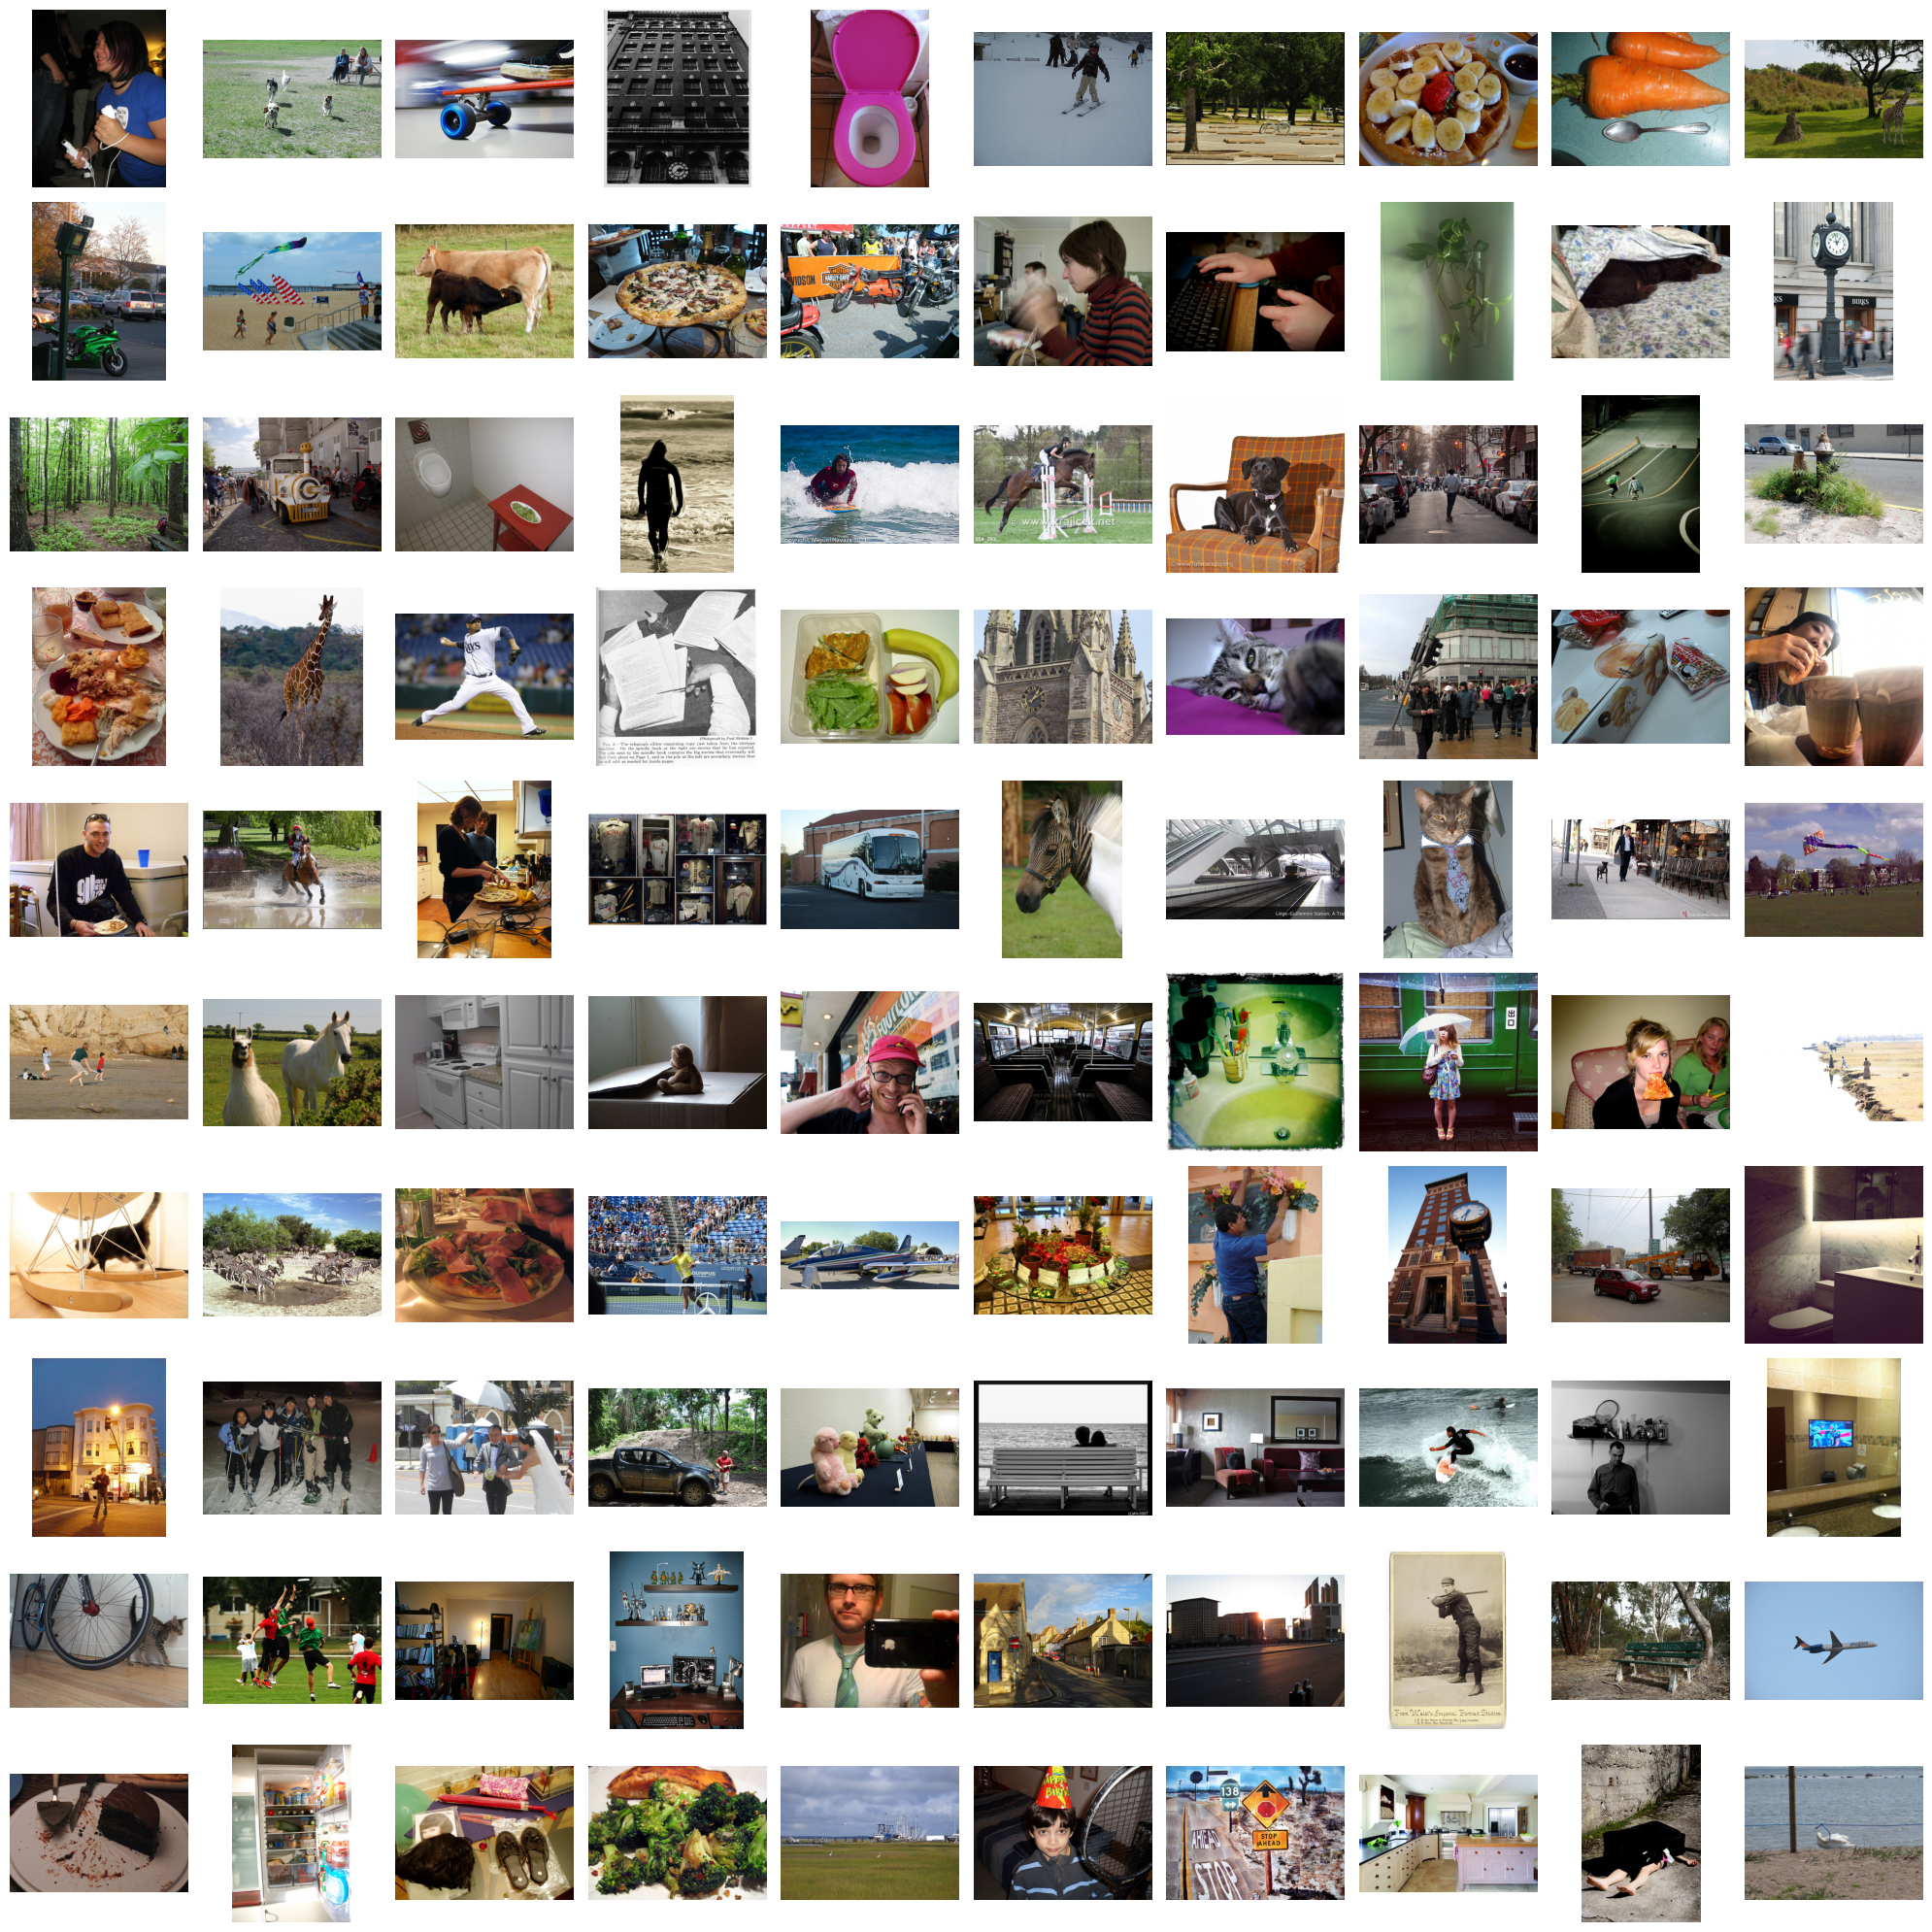

In [ ]:
import os
import json
import requests
import matplotlib.pyplot as plt
from PIL import Image

# 1. Define paths
test_ids_path = "/content/drive/MyDrive/COCO_Project/reports/test_100_image_ids.json"
test_images_dir = "/content/drive/MyDrive/COCO_Project/images/test"
contact_sheet_path = "/content/drive/MyDrive/COCO_Project/reports/test_contact_sheet.jpg"

os.makedirs(test_images_dir, exist_ok=True)

# 2. Load the locked-in IDs
with open(test_ids_path, "r") as f:
    final_100_ids = json.load(f)

# 3. Download the 100 images (with skip logic)
base_url = "http://images.cocodataset.org/val2017/"
print(f"Downloading 100 test images to {test_images_dir}...")

downloaded = 0
for img_id in final_100_ids:
    file_name = f"{img_id:012d}.jpg"
    save_path = os.path.join(test_images_dir, file_name)

    if not os.path.exists(save_path):
        url = base_url + file_name
        try:
            # 10 second timeout prevents hanging
            response = requests.get(url, timeout=10)
            response.raise_for_status()
            with open(save_path, "wb") as f:
                f.write(response.content)
            downloaded += 1
        except Exception as e:
            print(f"Failed to download {file_name}: {e}")

print(f"✅ Download complete. {downloaded} new images retrieved.\n")

# 4. Generate the 10x10 Visual Contact Sheet
print("Generating visual contact sheet... (This takes a moment)")
fig, axes = plt.subplots(10, 10, figsize=(20, 20))
axes = axes.flatten()

for i, img_id in enumerate(final_100_ids):
    file_name = f"{img_id:012d}.jpg"
    img_path = os.path.join(test_images_dir, file_name)

    if os.path.exists(img_path):
        # Open the image and plot it on the grid
        img = Image.open(img_path).convert("RGB")
        axes[i].imshow(img)

    axes[i].axis("off") # Remove axes for a clean look

plt.tight_layout()
plt.savefig(contact_sheet_path, dpi=150, bbox_inches='tight')
print(f"💾 Contact sheet securely saved to: {contact_sheet_path}")

# Display the contact sheet directly in Colab
plt.show()

In [ ]:
import json
import os
import re

def clean_caption(text):
    """
    Standardized cleaning for RAG indexing.
    """
    # 1. Lowercase everything
    text = text.lower()

    # 2. Remove punctuation (keeps only letters, numbers, and spaces)
    text = re.sub(r'[^\w\s]', '', text)

    # 3. Normalize whitespace (turns double spaces into a single space)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# 1. Load your perfectly formatted 50,000 training captions
train_path = "/content/drive/MyDrive/COCO_Project/annotations/train_captions.json"
print("Loading training captions for preprocessing...")
with open(train_path, "r") as f:
    train_data = json.load(f)

# 2. Apply cleaning rules while preserving the raw text
print("Cleaning text and restructuring JSON fields...")
for item in train_data:
    # Rename the original 'captions' key to 'raw_captions' to prevent leakage
    item["raw_captions"] = item.pop("captions")

    # Create the new 'clean_captions' list
    item["clean_captions"] = [clean_caption(c) for c in item["raw_captions"]]

# 3. Save the final preprocessed text dataset
cleaned_dir = "/content/drive/MyDrive/COCO_Project/cleaned"
os.makedirs(cleaned_dir, exist_ok=True)

processed_save_path = os.path.join(cleaned_dir, "train_captions_processed.json")
with open(processed_save_path, "w") as f:
    json.dump(train_data, f, indent=2)

print(f"✅ Success! Processed captions safely stored in: {processed_save_path}\n")

# Let's inspect one example to prove it worked
sample = train_data[0]
print(f"Example Image ID: {sample['image_id']}")
print(f"RAW:   {sample['raw_captions'][0]}")
print(f"CLEAN: {sample['clean_captions'][0]}")

Loading training captions for preprocessing...
Cleaning text and restructuring JSON fields...
✅ Success! Processed captions safely stored in: /content/drive/MyDrive/COCO_Project/cleaned/train_captions_processed.json

Example Image ID: 574769
RAW:   A woman in a room with a cat.
CLEAN: a woman in a room with a cat


--- 1. Creating Validation Split ---
✅ Extracted 100 validation IDs from training set.
💾 Saved to: /content/drive/MyDrive/COCO_Project/reports/validation_100_image_ids.json

--- 2. Analyzing Caption Lengths ---
Total captions analyzed: 50,000
Average caption length: 10.46 words
📊 Histogram saved to: /content/drive/MyDrive/COCO_Project/reports/caption_length_histogram.png


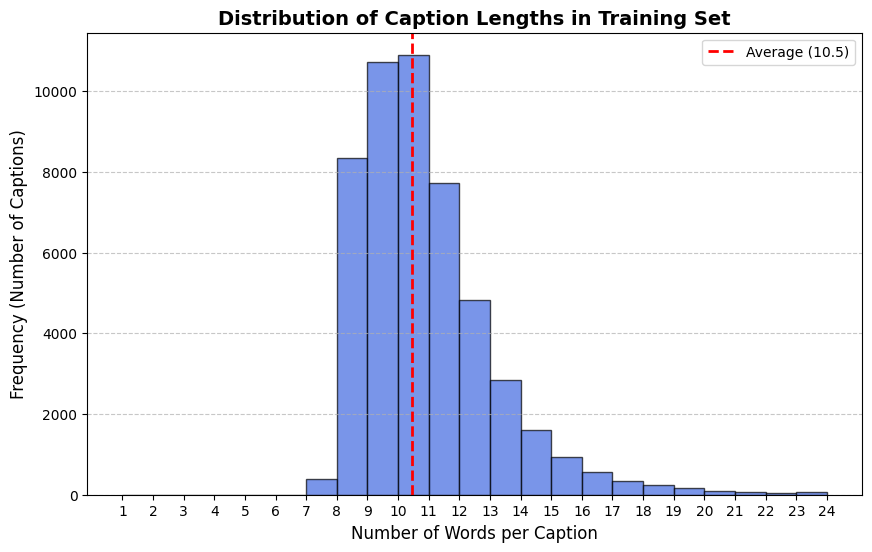

In [ ]:
import json
import os
import random
import matplotlib.pyplot as plt

# --- 1. THE VALIDATION SPLIT ---
print("--- 1. Creating Validation Split ---")
train_ids_path = "/content/drive/MyDrive/COCO_Project/reports/train_10000_image_ids.json"

with open(train_ids_path, "r") as f:
    train_10000_ids = json.load(f)

# Randomly select 100 images from the 10,000 using a fixed seed
random.seed(42)
validation_100_ids = random.sample(train_10000_ids, 100)

val_save_path = "/content/drive/MyDrive/COCO_Project/reports/validation_100_image_ids.json"
with open(val_save_path, "w") as f:
    json.dump(validation_100_ids, f)

print(f"✅ Extracted 100 validation IDs from training set.")
print(f"💾 Saved to: {val_save_path}\n")


# --- 2. DATA EXPLORATION: CAPTION LENGTHS ---
print("--- 2. Analyzing Caption Lengths ---")
captions_path = "/content/drive/MyDrive/COCO_Project/cleaned/train_captions_processed.json"

with open(captions_path, "r") as f:
    captions_data = json.load(f)

caption_lengths = []
for item in captions_data:
    for cap in item["clean_captions"]:
        # Count the number of words by splitting at spaces
        words = cap.split()
        caption_lengths.append(len(words))

avg_length = sum(caption_lengths) / len(caption_lengths)
print(f"Total captions analyzed: {len(caption_lengths):,}")
print(f"Average caption length: {avg_length:.2f} words")

# Create the Matplotlib Histogram
plt.figure(figsize=(10, 6))
plt.hist(caption_lengths, bins=range(1, 25), color='royalblue', edgecolor='black', alpha=0.7)
plt.axvline(avg_length, color='red', linestyle='dashed', linewidth=2, label=f'Average ({avg_length:.1f})')

plt.title("Distribution of Caption Lengths in Training Set", fontsize=14, fontweight='bold')
plt.xlabel("Number of Words per Caption", fontsize=12)
plt.ylabel("Frequency (Number of Captions)", fontsize=12)
plt.xticks(range(1, 25))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Save the visualization to your reports folder
vis_save_path = "/content/drive/MyDrive/COCO_Project/reports/caption_length_histogram.png"
plt.savefig(vis_save_path, dpi=300, bbox_inches='tight')
print(f"📊 Histogram saved to: {vis_save_path}")

plt.show()

Loading data for object count analysis...
Total images analyzed: 10,000
Average objects per image: 7.26
📊 Histogram securely saved to: /content/drive/MyDrive/COCO_Project/reports/object_count_histogram.png


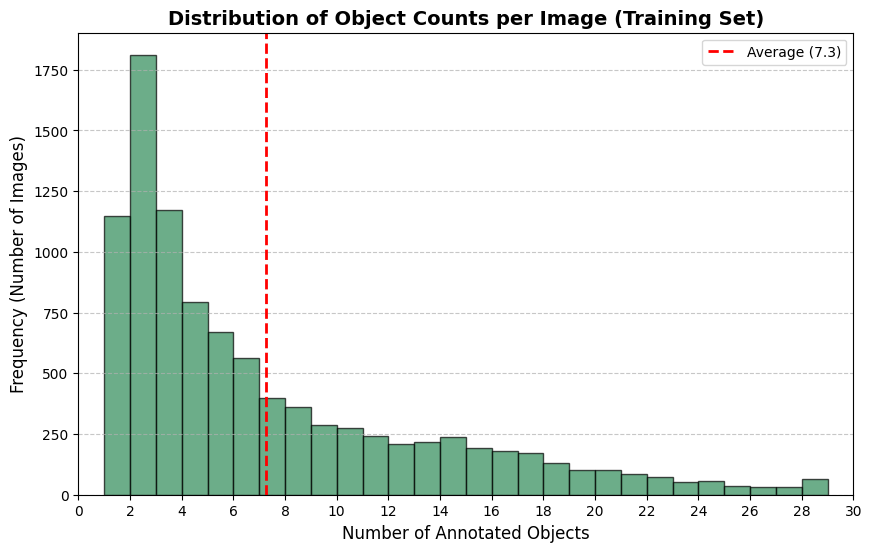

In [ ]:
import json
import matplotlib.pyplot as plt
from collections import defaultdict
import os

print("Loading data for object count analysis...")

# 1. Load our locked-in 10,000 training IDs (convert to a set for instant lookup)
train_ids_path = "/content/drive/MyDrive/COCO_Project/reports/train_10000_image_ids.json"
with open(train_ids_path, "r") as f:
    train_10000_ids = set(json.load(f))

# 2. Load the original training instance annotations
instances_path = "/content/drive/MyDrive/COCO_Project/annotations/annotations/instances_train2017.json"
with open(instances_path, "r") as f:
    instances_data = json.load(f)

# 3. Count how many objects are in each of our 10,000 images
object_counts = defaultdict(int)
for ann in instances_data["annotations"]:
    if ann["image_id"] in train_10000_ids:
        object_counts[ann["image_id"]] += 1

# Extract the counts into a simple list (including images that might have 0 annotations)
counts_list = [object_counts.get(img_id, 0) for img_id in train_10000_ids]
avg_objects = sum(counts_list) / len(counts_list)

print(f"Total images analyzed: {len(counts_list):,}")
print(f"Average objects per image: {avg_objects:.2f}")

# 4. Create the Matplotlib Histogram
plt.figure(figsize=(10, 6))
# We limit the x-axis to 30 because a few images might have 80+ tiny objects, which squishes the graph
plt.hist(counts_list, bins=range(1, 30), color='seagreen', edgecolor='black', alpha=0.7)
plt.axvline(avg_objects, color='red', linestyle='dashed', linewidth=2, label=f'Average ({avg_objects:.1f})')

plt.title("Distribution of Object Counts per Image (Training Set)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Annotated Objects", fontsize=12)
plt.ylabel("Frequency (Number of Images)", fontsize=12)
plt.xlim(0, 30)
plt.xticks(range(0, 31, 2))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 5. Save the visualization
vis_save_path = "/content/drive/MyDrive/COCO_Project/reports/object_count_histogram.png"
plt.savefig(vis_save_path, dpi=300, bbox_inches='tight')
print(f"📊 Histogram securely saved to: {vis_save_path}")

plt.show()

In [ ]:
# Install the library that makes using CLIP incredibly easy
!pip install -q sentence-transformers Pillow

import torch
from sentence_transformers import SentenceTransformer
from PIL import Image
import numpy as np

# 1. Load the CLIP model
# We use 'clip-ViT-B-32' because it is highly efficient and perfectly balances speed and accuracy
print("Downloading and loading CLIP model... (Takes about 30 seconds)")
model = SentenceTransformer('clip-ViT-B-32')

# 2. Setup our test data (using our familiar Image ID 574769)
test_image_id = 574769
image_path = f"/content/drive/MyDrive/COCO_Project/images/train/{test_image_id:012d}.jpg"

print(f"Loading image {test_image_id}...")
img = Image.open(image_path).convert("RGB")

# We will use a couple of the cleaned captions we generated earlier for this exact image
test_captions = [
    "a woman in a room with a cat",
    "a cat and a woman in a room",
    "a woman sitting in a chair with a cat"
]

# 3. Generate the embeddings! (This is the magic step)
print("Generating mathematical embeddings...")
image_embedding = model.encode(img)
text_embeddings = model.encode(test_captions)

# 4. Verify the dimensions and look at the actual numbers
print("\n--- Embedding Verification ---")
print(f"Image vector shape: {image_embedding.shape} (Should be 512)")
print(f"Text matrix shape: {text_embeddings.shape} (Should be 3 x 512)")

# Let's peek at the first 5 numbers of the image's mathematical representation
print(f"First 5 dimensions of the image vector:\n{image_embedding[:5].round(3)}")

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

0_CLIPModel/model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

0_CLIPModel/model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loading image 574769...
Generating mathematical embeddings...

--- Embedding Verification ---
Image vector shape: (512,) (Should be 512)
Text matrix shape: (3, 512) (Should be 3 x 512)
First 5 dimensions of the image vector:
[-0.522  0.371 -0.225  0.405 -0.184]


In [ ]:
import json
import os
import numpy as np
from sentence_transformers import SentenceTransformer
from PIL import Image

# 1. Setup the Model and Batch Configuration
model_name = 'clip-ViT-B-32'
print(f"Loading {model_name}...")
model = SentenceTransformer(model_name)
batch_size = 32 # Processing 32 items simultaneously on the GPU

# Define directories
processed_json_path = "/content/drive/MyDrive/COCO_Project/cleaned/train_captions_processed.json"
image_dir = "/content/drive/MyDrive/COCO_Project/images/train"
embed_dir = "/content/drive/MyDrive/COCO_Project/embeddings"
os.makedirs(embed_dir, exist_ok=True)

# 2. Prepare the Data
print("Preparing data lists...")
with open(processed_json_path, "r") as f:
    train_data = json.load(f)

image_paths = []
image_ids = []
all_clean_captions = []
caption_image_mapping = [] # Critical: tracks which text belongs to which image

for item in train_data:
    img_id = item["image_id"]
    img_path = os.path.join(image_dir, f"{img_id:012d}.jpg")

    image_paths.append(img_path)
    image_ids.append(img_id)

    # Flatten the 50,000 captions into one big list
    for cap in item["clean_captions"]:
        all_clean_captions.append(cap)
        caption_image_mapping.append(img_id)

# 3. Generate Text Embeddings (50,000 items)
print(f"\n--- Encoding {len(all_clean_captions):,} Text Captions ---")
text_embeddings = model.encode(all_clean_captions, batch_size=batch_size, show_progress_bar=True)

# 4. Generate Image Embeddings (10,000 items)
print(f"\n--- Encoding {len(image_paths):,} Images (This takes a few minutes) ---")
# PIL lazy-loads images, so this won't crash your RAM
images = [Image.open(p).convert("RGB") for p in image_paths]
image_embeddings = model.encode(images, batch_size=batch_size, show_progress_bar=True)

# 5. Save the Tensors to .npy files
print("\nSaving .npy embedding files to Google Drive...")
np.save(os.path.join(embed_dir, "train_text_embeddings.npy"), text_embeddings)
np.save(os.path.join(embed_dir, "train_image_embeddings.npy"), image_embeddings)

# Save the ID mappings so your RAG system knows how to retrieve them later
with open(os.path.join(embed_dir, "train_embedding_mapping.json"), "w") as f:
    json.dump({"image_ids": image_ids, "caption_mapping": caption_image_mapping}, f)

# 6. Generate the Mandatory Phase 1 Documentation
documentation = {
    "model_version": model_name,
    "embedding_dimensions": 512,
    "batch_size": batch_size,
    "normalization": "L2 normalized natively by sentence-transformers CLIP",
    "total_image_embeddings": len(image_embeddings),
    "total_text_embeddings": len(text_embeddings)
}
doc_path = os.path.join(embed_dir, "embedding_metadata.json")
with open(doc_path, "w") as f:
    json.dump(documentation, f, indent=2)

print(f"✅ Embeddings securely saved!")
print(f"✅ Phase 1 Documentation generated at: {doc_path}")

Loading clip-ViT-B-32...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Preparing data lists...

--- Encoding 50,000 Text Captions ---


Batches:   0%|          | 0/1563 [00:00<?, ?it/s]


--- Encoding 10,000 Images (This takes a few minutes) ---


In [ ]:
import json
import os
import numpy as np
from sentence_transformers import SentenceTransformer
from PIL import Image

# 1. Setup the Model
model_name = 'clip-ViT-B-32'
print(f"Loading {model_name}...")
model = SentenceTransformer(model_name)
batch_size = 32

# Define directories
processed_json_path = "/content/drive/MyDrive/COCO_Project/cleaned/train_captions_processed.json"
image_dir = "/content/drive/MyDrive/COCO_Project/images/train"
embed_dir = "/content/drive/MyDrive/COCO_Project/embeddings"
os.makedirs(embed_dir, exist_ok=True)

# 2. Prepare the Data Lists
print("Preparing data lists...")
with open(processed_json_path, "r") as f:
    train_data = json.load(f)

image_paths = []
image_ids = []
all_clean_captions = []
caption_image_mapping = []

for item in train_data:
    img_id = item["image_id"]
    image_paths.append(os.path.join(image_dir, f"{img_id:012d}.jpg"))
    image_ids.append(img_id)

    for cap in item["clean_captions"]:
        all_clean_captions.append(cap)
        caption_image_mapping.append(img_id)

# 3. Generate Text Embeddings
print(f"\n--- Encoding {len(all_clean_captions):,} Text Captions ---")
text_embeddings = model.encode(all_clean_captions, batch_size=batch_size, show_progress_bar=True)

# 4. Generate Image Embeddings (MEMORY EFFICIENT LOOP)
print(f"\n--- Encoding {len(image_paths):,} Images (Memory Efficient Mode) ---")
chunk_size = 500 # We only load 500 images into RAM at a time!
image_embeddings_list = []

for i in range(0, len(image_paths), chunk_size):
    chunk_paths = image_paths[i:i + chunk_size]

    # Load just this small chunk of images
    chunk_images = [Image.open(p).convert("RGB") for p in chunk_paths]

    # Encode them
    chunk_emb = model.encode(chunk_images, batch_size=batch_size, show_progress_bar=False)
    image_embeddings_list.append(chunk_emb)

    print(f"✅ Processed {min(i + chunk_size, len(image_paths)):,}/{len(image_paths):,} images...")

# Stitch all the chunks back together into a single master matrix
image_embeddings = np.vstack(image_embeddings_list)

# 5. Save the Tensors to .npy files
print("\nSaving .npy embedding files to Google Drive...")
np.save(os.path.join(embed_dir, "train_text_embeddings.npy"), text_embeddings)
np.save(os.path.join(embed_dir, "train_image_embeddings.npy"), image_embeddings)

with open(os.path.join(embed_dir, "train_embedding_mapping.json"), "w") as f:
    json.dump({"image_ids": image_ids, "caption_mapping": caption_image_mapping}, f)

# 6. Generate the Mandatory Phase 1 Documentation
documentation = {
    "model_version": model_name,
    "embedding_dimensions": 512,
    "batch_size": batch_size,
    "normalization": "L2 normalized natively by sentence-transformers CLIP",
    "total_image_embeddings": len(image_embeddings),
    "total_text_embeddings": len(text_embeddings)
}
doc_path = os.path.join(embed_dir, "embedding_metadata.json")
with open(doc_path, "w") as f:
    json.dump(documentation, f, indent=2)

print(f"\n✅ Embeddings securely saved!")
print(f"✅ Phase 1 Documentation generated at: {doc_path}")

Loading clip-ViT-B-32...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Preparing data lists...

--- Encoding 50,000 Text Captions ---


Batches:   0%|          | 0/1563 [00:00<?, ?it/s]


--- Encoding 10,000 Images (Memory Efficient Mode) ---
✅ Processed 500/10,000 images...
✅ Processed 1,000/10,000 images...
✅ Processed 1,500/10,000 images...
✅ Processed 2,000/10,000 images...
✅ Processed 2,500/10,000 images...
✅ Processed 3,000/10,000 images...
✅ Processed 3,500/10,000 images...
✅ Processed 4,000/10,000 images...
✅ Processed 4,500/10,000 images...
✅ Processed 5,000/10,000 images...
✅ Processed 5,500/10,000 images...
✅ Processed 6,000/10,000 images...
✅ Processed 6,500/10,000 images...
✅ Processed 7,000/10,000 images...
✅ Processed 7,500/10,000 images...
✅ Processed 8,000/10,000 images...
✅ Processed 8,500/10,000 images...
✅ Processed 9,000/10,000 images...
✅ Processed 9,500/10,000 images...
✅ Processed 10,000/10,000 images...

Saving .npy embedding files to Google Drive...

✅ Embeddings securely saved!
✅ Phase 1 Documentation generated at: /content/drive/MyDrive/COCO_Project/embeddings/embedding_metadata.json
